# **Caderno para a análise de corpus textual para TTS**

Adina Vladu, María Pérez Lago
(2026)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


Este caderno permíteche facer unha análise estatística dsa modalidades declarativas e lonxitudes oracionais presentes nun corpus textual para síntese de voz (TTS), que te axudará a entender e visualizar os teus datos e establecer unha estratexia para mellorar os datos de adestramento de modelos baseados nestes corpus.

Obterás:

  - **unha estatística do tipo de frases** (declarativas, interrogativas, exclamativas, con puntos suspensivos, que combinan as demais, así como as frases sen puntuación final, en caso de que exista).

  Por que é importante? Os modelos TTS adestrados por redes neuronais "aprenden" dos datos que ven. Se non hai suficiente representación dos diferentes tipos de frases, terán dificultades en reproducir a prosodia correcta. No caso das frases interrogativas e exclamativas, estas deben representar, como mínimo, un 15% do total e debe haber representación dos diferentes tipos (por exemplo, interrogativas totais e parciais).

  - **unha estatística da lonxitude das frases** (desde unha palabra ata x) - en xeral e por modalidades oracionais.
  
  Por que é importante? A distribución das frases nun corpus TTS, idealmente, debería seguír unha distribución normal (curva de Gauss), é dicir, visualizaríase nunha forma de campá, co groso do corpus composto por frases de lonxitude media. Non obstante, especialmente importante é a presenza de suficientes frases dunha palabra (de todos os tipos: declarativas, interrogativas, exclamativas...), xa que a súa infrarrepresentación no corpus resulta en que o modelo teña dificultades á hora de sintetizar ese tipo de frases (mala pronuncia ou prosodia).

  **Referencias:**

  https://github.com/coqui-ai/TTS/wiki/What-makes-a-good-TTS-dataset

  https://huggingface.co/learn/audio-course/chapter6/tts_datasets





# **1. Análise do tipo de frases dun corpus textual para TTS**


Para comezar, importamos as librerías necesarias.
No Colab, a orde de executar as celas é importante, xa que as librerías precisan estar cargadas para continuar. Unha vez que a cela está correctamente executada, mostrarase unha marca verde de execución.

In [3]:
import re
import os
import matplotlib.pyplot as plt
from google.colab import files
from collections import Counter
import matplotlib.pyplot as plt
import pandas as pd
import re
import numpy as np
from scipy.stats import norm

Nas celas de código que seguen a continuación, todo o que está marcado con # representan comentarios que axudan a entender que é o que fai cada bloque de código.

In [4]:
# Establecer as categorías das frases
def analyze_sentences(file_path):
    sentence_lengths = {}
    categories = {
        "Interrogativas": 0,
        "Exclamativas": 0,
        "Acabadas en '...'": 0,
        "Mixtas (combinan ?, ! e /ou ...)": 0,
        "Declarativas con '.'": 0,
        "Declarativas sen '.'": 0
    }
    total_sentences = 0

    with open(file_path, 'r', encoding='utf-8') as file:
        for line in file:
            sentence = line.strip()

            # Contar as palabras de cada frase (1 frase = 1 liña)
            word_count = len(re.findall(r'\b\w+\b', sentence))
            sentence_lengths[word_count] = sentence_lengths.get(word_count, 0) + 1

            # Clasificar en tipos
            if sentence.endswith('?'):
                categories["Interrogativas"] += 1
            elif sentence.endswith('!'):
                categories["Exclamativas"] += 1
            elif sentence.endswith('...'):
                categories["Acabadas en '...'"] += 1
            elif re.search(r'[?!...]', sentence[:-1]):
                categories["Mixtas (combinan ?, ! e /ou ...)"] += 1
            elif sentence.endswith('.'):
                categories["Declarativas con '.'"] += 1
            elif re.search(r'[a-záéíóúñïü:;,/-]$', sentence[:-1], re.IGNORECASE):
                categories["Declarativas sen '.'"] += 1

            total_sentences += 1

    # Función para imprimir o resultado en pantalla
    print("\nAnálise por tipos de frases:")
    for category, count in categories.items():
        percentage = (count / total_sentences) * 100
        print(f"{category}: {count} frases ({percentage:.2f}%)")

    # Función para crear a gráfica de porcentaxes
    labels = list(categories.keys())
    values = [(count / total_sentences) * 100 for count in categories.values()]

    plt.figure(figsize=(10, 6))
    plt.barh(labels, values, color=['blue', 'green', 'red', 'purple', 'orange', 'cyan'])
    plt.xlabel("Porcentaxe (%)")
    plt.ylabel("Categoría de frases")
    plt.title("Distribución de tipos de frases")
    plt.xlim(0, 100)
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.show()

In [5]:
# Subimos ao Colab o ficheiro de texto para analizar
uploaded = files.upload()
file_path = list(uploaded.keys())[0]

Saving paulo_maius.txt to paulo_maius.txt



Análise por tipos de frases:
Interrogativas: 270 frases (20.52%)
Exclamativas: 121 frases (9.19%)
Acabadas en '...': 84 frases (6.38%)
Mixtas (combinan ?, ! e /ou ...): 7 frases (0.53%)
Declarativas con '.': 834 frases (63.37%)
Declarativas sen '.': 0 frases (0.00%)


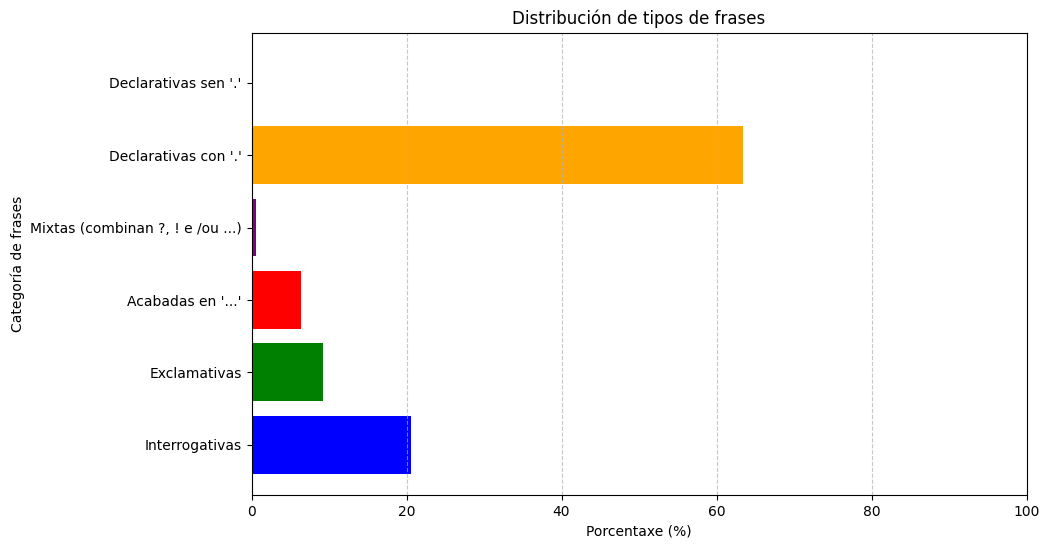

In [6]:
# Executamos a análise por tipo de frases e a gráfica correspondente
analyze_sentences(file_path)

# **2. Estatísticas da lonxitude das frases**

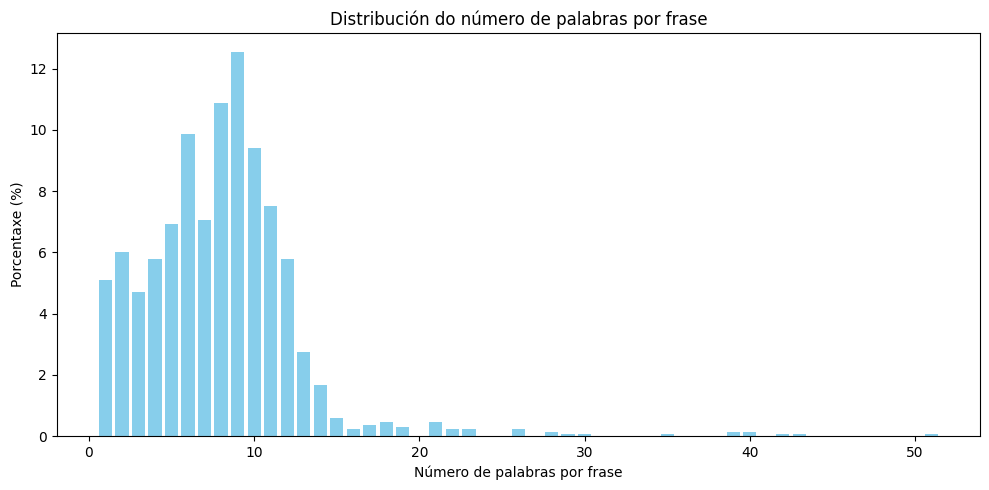


Total de frases: 1316
Total de palabras: 10467
Ficheiro gardado como: analise_num_palabras.txt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
# Análise de frases por número de palabras e total de palabras no corpus
def analyze_sentences(file_path):
    sentence_lengths = {}
    total_sentences = 0
    total_words = 0

    with open(file_path, 'r', encoding='utf-8') as file:
        for line in file:
            sentence = line.strip()
            word_count = len(re.findall(r'\b\w+\b', sentence))
            sentence_lengths[word_count] = sentence_lengths.get(word_count, 0) + 1
            total_sentences += 1
            total_words += word_count

    return sentence_lengths, total_sentences, total_words

# Visualización + exportación
def plot_sentence_lengths(sentence_lengths, total_sentences, total_words):
    lengths = sorted(sentence_lengths.keys())
    counts = [sentence_lengths[l] for l in lengths]
    percentages = [(c / total_sentences) * 100 for c in counts]

    plt.figure(figsize=(10, 5))
    plt.bar(lengths, percentages, color='skyblue')
    plt.xlabel('Número de palabras por frase')
    plt.ylabel('Porcentaxe (%)')
    plt.title('Distribución do número de palabras por frase')
    plt.tight_layout()
    plt.show()

    # Crear ficheiro descargable cos resultados
    output_file = "analise_num_palabras.txt"
    with open(output_file, "w", encoding="utf-8") as f:
        f.write(f"TOTAL DE FRASES: {total_sentences}\n")
        f.write(f"TOTAL DE PALABRAS: {total_words}\n\n")
        f.write("Número de palabras\tNº frases\tPorcentaxe (%)\n")
        for length, count in zip(lengths, counts):
            percentage = (count / total_sentences) * 100
            f.write(f"{length}\t{count}\t{percentage:.2f}\n")

    print(f"\nTotal de frases: {total_sentences}")
    print(f"Total de palabras: {total_words}")
    print(f"Ficheiro gardado como: {output_file}")
    files.download(output_file)

# Execución
sentence_lengths, total_sentences, total_words = analyze_sentences(file_path)
plot_sentence_lengths(sentence_lengths, total_sentences, total_words)


De forma opcional, podemos visualizar como se compara a distribución da lonxitude das frases do noso corpus cunha distribución normal.

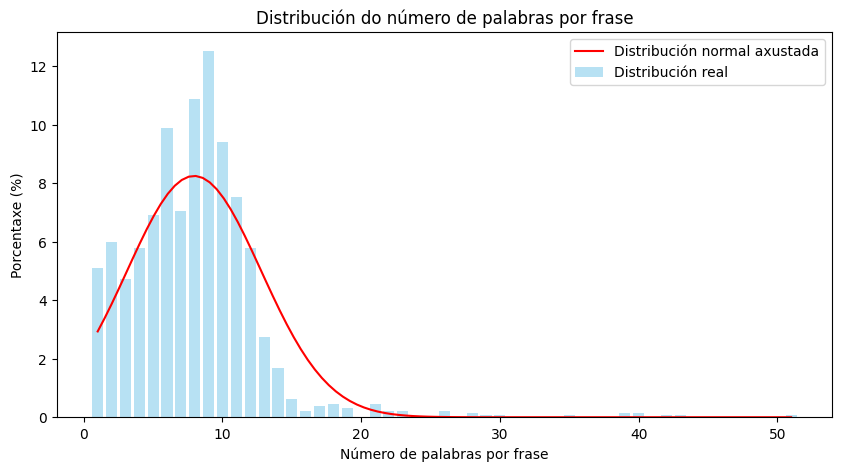

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
import re

def analyze_sentences(file_path):
    sentence_lengths = {}
    total_sentences = 0

    with open(file_path, 'r', encoding='utf-8') as file:
        for line in file:
            sentence = line.strip()
            word_count = len(re.findall(r'\b\w+\b', sentence))
            sentence_lengths[word_count] = sentence_lengths.get(word_count, 0) + 1
            total_sentences += 1

    return sentence_lengths, total_sentences

# Visualización 2
def plot_sentence_lengths(sentence_lengths, total_sentences):
    lengths = sorted(sentence_lengths.keys())
    counts = [sentence_lengths[l] for l in lengths]
    percentages = [(c / total_sentences) * 100 for c in counts]

    # Calcular a distribución normal
    data = np.array([l for l in lengths for _ in range(sentence_lengths[l])])
    mean, std = norm.fit(data)

    # Visualización
    plt.figure(figsize=(10, 5))
    plt.bar(lengths, percentages, color='skyblue', alpha=0.6, label='Distribución real')

    # Sobrepor a curva da distribución normal
    x = np.linspace(min(lengths), max(lengths), 100)
    bin_width = 1  # Because you're using integer word counts
    p = norm.pdf(x, mean, std) * bin_width * 100  # Scale to percentage

    plt.plot(x, p, 'r', label='Distribución normal axustada')
    plt.xlabel('Número de palabras por frase')
    plt.ylabel('Porcentaxe (%)')
    plt.title('Distribución do número de palabras por frase')
    plt.legend()
    plt.show()

    # Execución
file_name = (file_path)
sentence_lengths, total_sentences = analyze_sentences(file_name)
plot_sentence_lengths(sentence_lengths, total_sentences)

A continuación, analizaremos a distribución de cada modalidade oracional e compararémola coa distribución total de frases no corpus.

Total de frases analizadas: 1316
Total de palabras: 10467
As estatísticas sen datos aparecen como «—».


,Nº frases,% do corpus,Media,Mediana,Desv. típica
Categoría,,,,,
Corpus completo,1316,100.00,7.95,8.00,4.83
Interrogativas,270,20.52,6.74,6.00,3.59
Exclamativas,121,9.19,4.31,4.00,2.54
Acabadas en '...',84,6.38,7.08,7.50,3.06
"Mixtas (combinan ?, ! e /ou ...)",7,0.53,11.86,10.00,5.74
Declarativas con '.',834,63.37,8.93,9.00,5.20
Declarativas sen '.',0,0.00,—,—,—


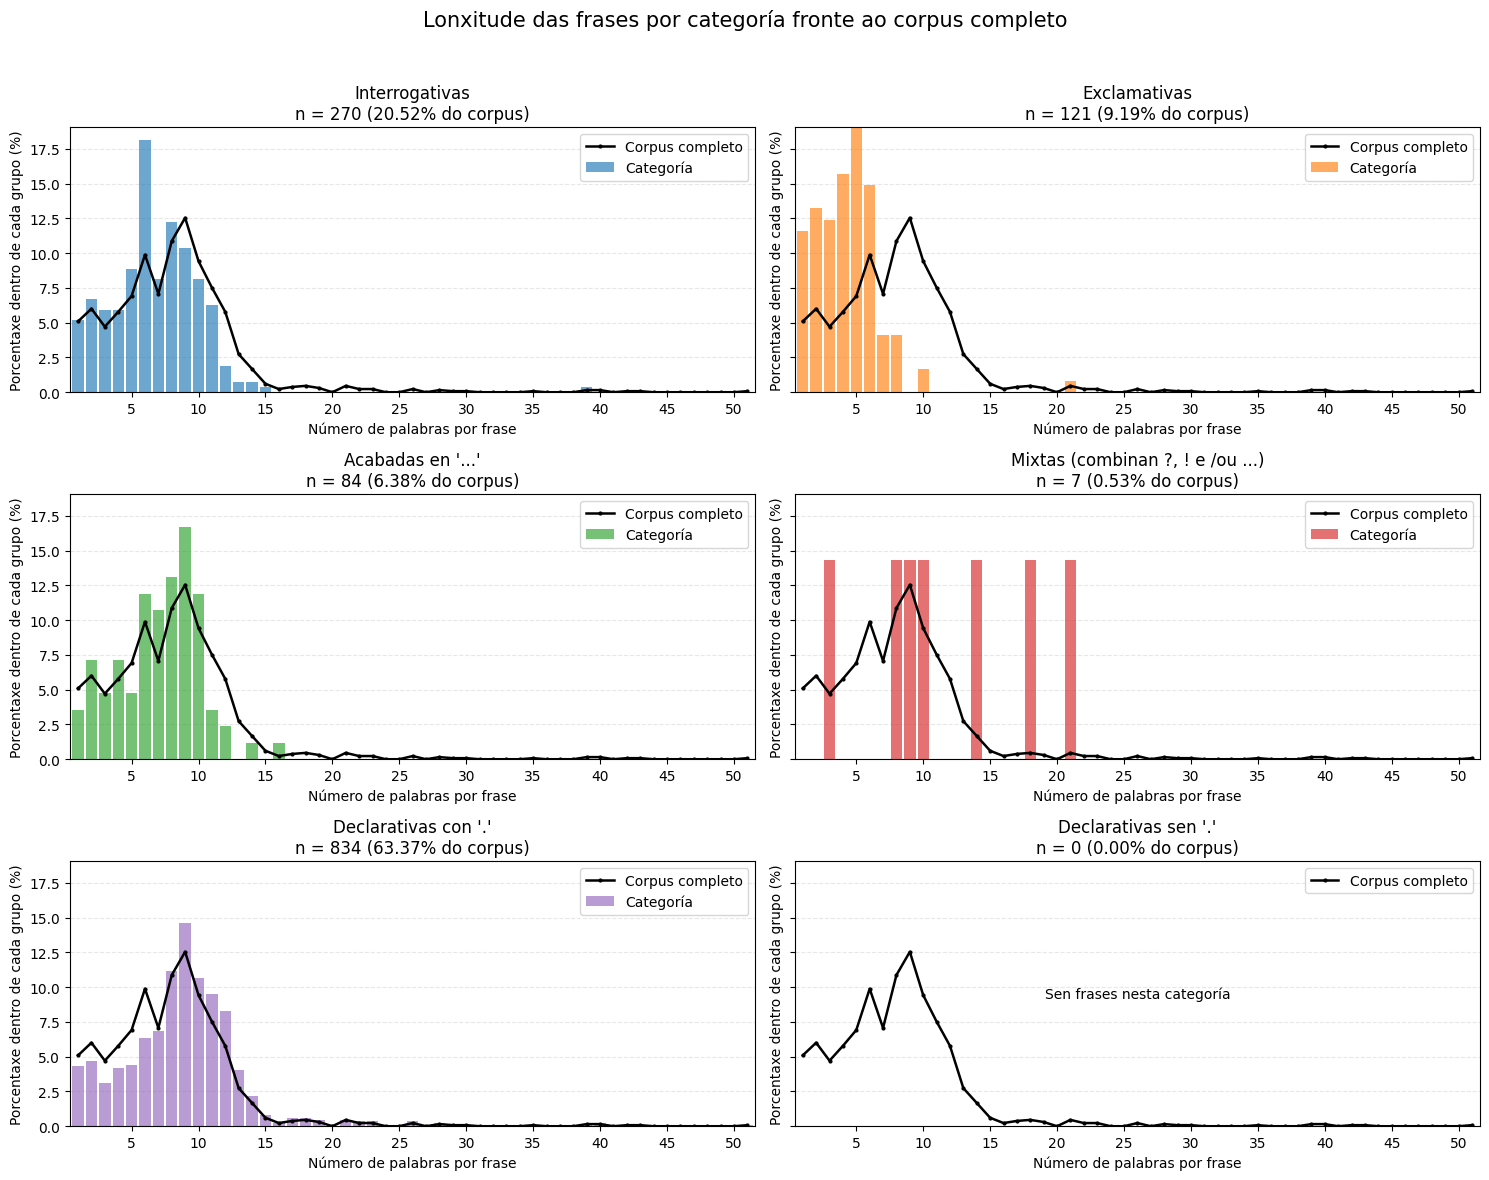

In [20]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

CATEGORIAS_TTS = [
    "Interrogativas",
    "Exclamativas",
    "Acabadas en '...'",
    "Mixtas (combinan ?, ! e /ou ...)",
    "Declarativas con '.'",
    "Declarativas sen '.'"
]


def clasificar_frase_tts(texto):
    if texto.endswith('?'):
        return "Interrogativas"
    elif texto.endswith('!'):
        return "Exclamativas"
    elif texto.endswith('...'):
        return "Acabadas en '...'"
    elif re.search(r'[?!...]', texto[:-1]):
        return "Mixtas (combinan ?, ! e /ou ...)"
    elif texto.endswith('.'):
        return "Declarativas con '.'"
    elif re.search(
        r'[a-záéíóúñïü:;,/-]$', texto[:-1], re.IGNORECASE
    ):
        return "Declarativas sen '.'"



def comparar_lonxitudes_tts(file_path):
    rexistros = []

    with open(file_path, "r", encoding="utf-8") as ficheiro:
        for numero_lina, lina in enumerate(ficheiro, start=1):
            texto = lina.strip()
            categoria = clasificar_frase_tts(texto)

            rexistros.append({
                "liña": numero_lina,
                "texto": texto,
                "categoría": categoria,
                "palabras": len(re.findall(r"\b\w+\b", texto))
            })

    if not rexistros:
        raise ValueError("O ficheiro está baleiro.")

    df = pd.DataFrame(rexistros)
    total = len(df)

    # Estatísticas por categoría.
    def resumir(nome, datos):
        n = len(datos)

        return {
            "Categoría": nome,
            "Nº frases": n,
            "% do corpus": 100 * n / total,
            "Media": datos.mean() if n else np.nan,
            "Mediana": datos.median() if n else np.nan,
            "Desv. típica": datos.std(ddof=0) if n else np.nan,
        }

    filas = [resumir("Corpus completo", df["palabras"])]

    for categoria in CATEGORIAS_TTS:
        datos = df.loc[df["categoría"] == categoria, "palabras"]
        filas.append(resumir(categoria, datos))

    resumo = pd.DataFrame(filas).set_index("Categoría")

    print(f"Total de frases analizadas: {total}")
    print(f"Total de palabras: {df['palabras'].sum()}")
    print("As estatísticas sen datos aparecen como «—».")

    display(resumo.style.format(precision=2, na_rep="—"))

    # Todas as lonxitudes.
    lonxitudes = np.arange(
        min(1, int(df["palabras"].min())),
        int(df["palabras"].max()) + 1
    )

    reconto_total = (
        df["palabras"]
        .value_counts()
        .reindex(lonxitudes, fill_value=0)
    )
    porcentaxe_total = 100 * reconto_total / total

    distribucion = pd.DataFrame({
        "Número de palabras": lonxitudes,
        "Corpus: nº frases": reconto_total.to_numpy(),
        "Corpus: %": porcentaxe_total.to_numpy()
    })

    fig, axes = plt.subplots(
        3, 2,
        figsize=(15, 12),
        sharex=True,
        sharey=True,
        squeeze=False
    )

    cores = plt.get_cmap("tab10").colors

    for i, categoria in enumerate(CATEGORIAS_TTS):
        ax = axes.flat[i]
        datos = df.loc[df["categoría"] == categoria, "palabras"]
        n = len(datos)

        reconto = (
            datos.value_counts()
            .reindex(lonxitudes, fill_value=0)
        )

        porcentaxe = (
            100 * reconto / n
            if n
            else pd.Series(np.nan, index=lonxitudes)
        )

        distribucion[f"{categoria}: nº frases"] = reconto.to_numpy()
        distribucion[f"{categoria}: %"] = porcentaxe.to_numpy()

        if n:
            ax.bar(
                lonxitudes,
                porcentaxe,
                width=0.85,
                color=cores[i],
                alpha=0.65,
                label="Categoría"
            )
        else:
            ax.text(
                0.5, 0.5,
                "Sen frases nesta categoría",
                transform=ax.transAxes,
                ha="center",
                va="center"
            )

        ax.plot(
            lonxitudes,
            porcentaxe_total,
            color="black",
            linewidth=1.8,
            marker=".",
            markersize=4,
            label="Corpus completo"
        )

        ax.set_title(
            f"{categoria}\n"
            f"n = {n} ({100 * n / total:.2f}% do corpus)"
        )
        ax.set_xlabel("Número de palabras por frase")
        ax.set_xticks(
        np.arange(0, int(df["palabras"].max()) + 1, 5)
        )
        ax.tick_params(axis="x", labelbottom=True)
        ax.set_ylabel("Porcentaxe dentro de cada grupo (%)")
        ax.set_xlim(lonxitudes[0] - 0.6, lonxitudes[-1] + 0.6)
        ax.set_ylim(bottom=0)
        ax.grid(axis="y", linestyle="--", alpha=0.3)
        ax.set_axisbelow(True)
        ax.legend()

    fig.suptitle(
        "Lonxitude das frases por categoría fronte ao corpus completo",
        fontsize=15
    )
    fig.tight_layout(rect=(0, 0, 1, 0.96))
    plt.show()

    return df, resumo, distribucion, fig


# Ruta do ficheiro que se vai analizar.
file_path = "/content/paulo_maius.txt"

df_modalidades, resumo_modalidades, distribucion_modalidades, figura_modalidades = (
    comparar_lonxitudes_tts(file_path)
)